# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [5]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/SATSolveGuided.csv',
        ),
        # pandas.read_csv(
          # 'results/SYN.csv',
        # )
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'])

In [6]:
strategies = data.strategy.unique()
strategies

array(['FirstAction', 'LeanCopCut', 'SATSolve', 'SATSolveGuided',
       'SATSolveGuidedProbeConflicts', 'SATSolveGuidedForcedTrue',
       'SATSolveGuidedEVSIDS', 'SATSolveGuidedShort',
       'SATSolveGuidedFast', 'SATSolveLiteral'], dtype=object)

In [7]:
# problems = data.xs(level = 'strategy', key = 'SATSolveGuided').index.str[:3].unique()
# data = data[data.index.get_level_values('problem').str[:3].isin(problems)]
# problems

In [8]:
# data = data.groupby(level = 'problem').filter(lambda x: x.solved.count() == len(strategies))

In [9]:
data.problem.str[:3].unique()

array(['AGT', 'ALG', 'ANA', 'BIO', 'BOO', 'CAT', 'COL', 'COM', 'CSR',
       'FLD', 'GEG', 'GEO', 'GRA', 'GRP', 'HAL', 'HEN', 'HWC', 'HWV',
       'ITP', 'KLE', 'KRS', 'LAT', 'LCL', 'LDA', 'MED', 'MGT', 'MSC',
       'MVA', 'NLP', 'NUM', 'NUN', 'PHI', 'PLA', 'PRD', 'PRO', 'PUZ',
       'REL', 'RNG', 'ROB', 'SCT', 'SET', 'SEU', 'SEV', 'SWB', 'SWC',
       'SWV', 'SWW', 'SYN', 'SYO', 'TOP'], dtype=object)

# Analysing

In [10]:
control = ['FirstAction', 'LeanCopCut']

In [11]:
data[data.solved]

,problem,strategy,status,solved,steps,time_ms,info,error
0,AGT001+1.p,FirstAction,solved,True,4.0,2.0,NaN,NaN
1,AGT001+1.p,LeanCopCut,solved,True,4.0,2.0,NaN,NaN
2,AGT001+1.p,SATSolve,solved,True,0.0,0.0,NaN,NaN
3,AGT001+1.p,SATSolveGuided,solved,True,0.0,0.0,NaN,NaN
4,AGT001+1.p,SATSolveGuidedProbeConflicts,solved,True,0.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...
161876,TOP005-2.p,SATSolveGuidedEVSIDS,solved,True,6296.0,18608.0,Theorem (SAT); score=1.0,NaN
161879,TOP005-2.p,SATSolveLiteral,solved,True,36879.0,45909.0,"Theorem (SAT); literal=choices:22065,forward:6...",NaN
161932,TOP026+1.p,SATSolve,solved,True,7476.0,22217.0,Theorem (SAT),NaN
161936,TOP026+1.p,SATSolveGuidedEVSIDS,solved,True,7476.0,25373.0,Theorem (SAT),NaN


In [12]:
data[data.solved].groupby('strategy').size()

strategy
FirstAction                     1654
LeanCopCut                      1817
SATSolve                        1807
SATSolveGuided                  1760
SATSolveGuidedEVSIDS            1799
SATSolveGuidedFast              1819
SATSolveGuidedForcedTrue        1773
SATSolveGuidedProbeConflicts    1743
SATSolveGuidedShort             1889
SATSolveLiteral                 2375
dtype: int64

# Results

<Axes: xlabel='strategy'>

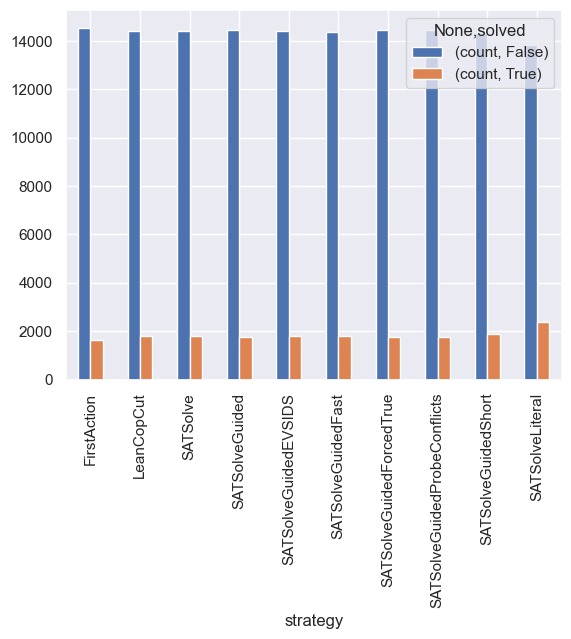

In [13]:
data.groupby('strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

In [30]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

Text(0.5, 1.0, 'Winners and losers of different SAT policies. Total of 16,213 problems.')

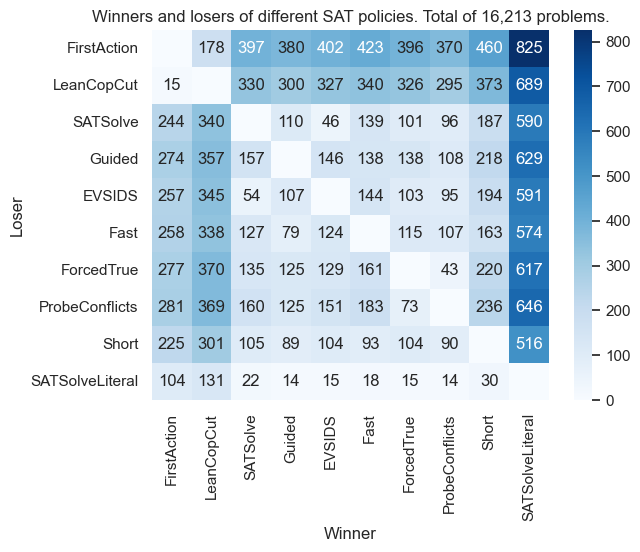

In [32]:
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
)

# cols = results.columns[results.columns.str.startswith('SAT') & ~results.columns.str.endswith('Literal')]
# cols = results.columns
# plot = (
#     results.
#     loc[cols, cols].
#     rename_axis(index = 'Loser', columns = 'Winner').
#     rename(index = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided').
#     rename(columns = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided')
# )

seaborn.heatmap(
    plot,
    annot = plot.map(lambda x: f'{x:d}' if x != 0 else ''),
    fmt = 's',
    cmap = 'Blues',
)
pyplot.title(f'Winners and losers of different SAT policies. Total of {data.problem.nunique():,d} problems.')
# pyplot.savefig('figures/sat_policies_plot.png', bbox_inches = 'tight')

Text(0.5, 1.0, 'Winners and losers of different SAT policies. Total of 7,805 problems.')

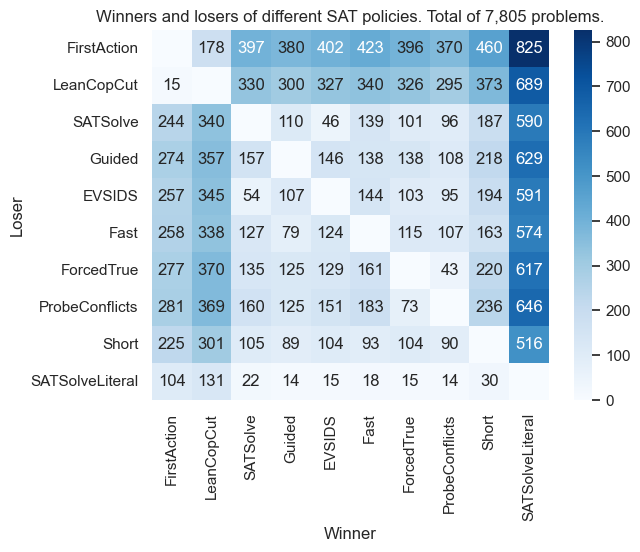

In [43]:
subset = merged[merged.problem.str.contains(r'-')]

results = (
    subset
    [~subset.solved_left & subset.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
)

# cols = results.columns[results.columns.str.startswith('SAT') & ~results.columns.str.endswith('Literal')]
# cols = results.columns
# plot = (
#     results.
#     loc[cols, cols].
#     rename_axis(index = 'Loser', columns = 'Winner').
#     rename(index = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided').
#     rename(columns = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided')
# )

seaborn.heatmap(
    plot,
    annot = plot.map(lambda x: f'{x:d}' if x != 0 else ''),
    fmt = 's',
    cmap = 'Blues',
)
pyplot.title(f'Winners and losers of different SAT policies. Total of {subset.problem.nunique():,d} problems.')
# pyplot.savefig('figures/sat_policies_plot.png', bbox_inches = 'tight')

In [16]:
data

,problem,strategy,status,solved,steps,time_ms,info,error
0,AGT001+1.p,FirstAction,solved,True,4.0,2.0,NaN,NaN
1,AGT001+1.p,LeanCopCut,solved,True,4.0,2.0,NaN,NaN
2,AGT001+1.p,SATSolve,solved,True,0.0,0.0,NaN,NaN
3,AGT001+1.p,SATSolveGuided,solved,True,0.0,0.0,NaN,NaN
4,AGT001+1.p,SATSolveGuidedProbeConflicts,solved,True,0.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...
162125,TOP052-1.p,SATSolveGuidedForcedTrue,timeout,False,134806.0,90000.0,NaN,NaN
162126,TOP052-1.p,SATSolveGuidedEVSIDS,timeout,False,141102.0,90001.0,NaN,NaN
162127,TOP052-1.p,SATSolveGuidedShort,timeout,False,134939.0,90000.0,NaN,NaN
162128,TOP052-1.p,SATSolveGuidedFast,timeout,False,135039.0,90000.0,NaN,NaN


In [17]:
pandas.concat(
    [
        merged[(merged.strategy_left == 'SATSolve') & (merged.strategy_right == x) & ~merged.solved_left & merged.solved_right].sample(2)
        for x in cols if x != 'SATSolve'
    ]
)[['strategy_right', 'problem', 'steps_right', 'time_ms_right']].to_csv()

',strategy_right,problem,steps_right,time_ms_right\n247820,FirstAction,GEO085+1.p,11787.0,14562.0\n1559820,FirstAction,SYN235-1.p,104756.0,83668.0\n1548521,LeanCopCut,SYN689-1.p,45899.0,41719.0\n109821,LeanCopCut,COL113-1.p,94.0,343.0\n716223,SATSolveGuided,NLP258-1.p,16053.0,58859.0\n1007923,SATSolveGuided,SET063-7.p,2342.0,3581.0\n1523326,SATSolveGuidedEVSIDS,SYN623-1.p,7065.0,14712.0\n1125526,SATSolveGuidedEVSIDS,SEU094+1.p,16213.0,56666.0\n1012928,SATSolveGuidedFast,SET199+3.p,16858.0,69540.0\n1128128,SATSolveGuidedFast,SEU165+2.p,15193.0,86500.0\n1171525,SATSolveGuidedForcedTrue,SEU326+1.p,16154.0,48729.0\n1162225,SATSolveGuidedForcedTrue,SEU117+1.p,12038.0,38876.0\n1558224,SATSolveGuidedProbeConflicts,SYN158-1.p,9060.0,27808.0\n1053924,SATSolveGuidedProbeConflicts,SET931+1.p,2764.0,2979.0\n768427,SATSolveGuidedShort,NUM329+1.p,10755.0,64083.0\n1514327,SATSolveGuidedShort,SYN332+1.p,39934.0,75552.0\n1569629,SATSolveLiteral,SYN553-1.p,32509.0,44333.0\n1113729,SATSolveLiteral,SEU245

In [18]:
results.rename(lambda x: x.removeprefix('SATSolve'))

winner,FirstAction,LeanCopCut,SATSolve,SATSolveGuided,SATSolveGuidedEVSIDS,SATSolveGuidedFast,SATSolveGuidedForcedTrue,SATSolveGuidedProbeConflicts,SATSolveGuidedShort,SATSolveLiteral
loser,,,,,,,,,,
FirstAction,0,178,397,380,402,423,396,370,460,825
LeanCopCut,15,0,330,300,327,340,326,295,373,689
,244,340,0,110,46,139,101,96,187,590
Guided,274,357,157,0,146,138,138,108,218,629
GuidedEVSIDS,257,345,54,107,0,144,103,95,194,591
GuidedFast,258,338,127,79,124,0,115,107,163,574
GuidedForcedTrue,277,370,135,125,129,161,0,43,220,617
GuidedProbeConflicts,281,369,160,125,151,183,73,0,236,646
GuidedShort,225,301,105,89,104,93,104,90,0,516


In [19]:
merged

,problem,strategy_left,status_left,solved_left,steps_left,time_ms_left,info_left,error_left,strategy_right,status_right,solved_right,steps_right,time_ms_right,info_right,error_right
0,AGT001+1.p,FirstAction,solved,True,4.0,2.0,NaN,NaN,FirstAction,solved,True,4.0,2.0,NaN,NaN
1,AGT001+1.p,FirstAction,solved,True,4.0,2.0,NaN,NaN,LeanCopCut,solved,True,4.0,2.0,NaN,NaN
2,AGT001+1.p,FirstAction,solved,True,4.0,2.0,NaN,NaN,SATSolve,solved,True,0.0,0.0,NaN,NaN
3,AGT001+1.p,FirstAction,solved,True,4.0,2.0,NaN,NaN,SATSolveGuided,solved,True,0.0,0.0,NaN,NaN
4,AGT001+1.p,FirstAction,solved,True,4.0,2.0,NaN,NaN,SATSolveGuidedProbeConflicts,solved,True,0.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1621295,TOP052-1.p,SATSolveLiteral,timeout,False,150296.0,90000.0,"literal=choices:74890,forward:5469595,unique:5...",NaN,SATSolveGuidedForcedTrue,timeout,False,134806.0,90000.0,NaN,NaN
1621296,TOP052-1.p,SATSolveLiteral,timeout,False,150296.0,90000.0,"literal=choices:74890,forward:5469595,unique:5...",NaN,SATSolveGuidedEVSIDS,timeout,False,141102.0,90001.0,NaN,NaN
1621297,TOP052-1.p,SATSolveLiteral,timeout,False,150296.0,90000.0,"literal=choices:74890,forward:5469595,unique:5...",NaN,SATSolveGuidedShort,timeout,False,134939.0,90000.0,NaN,NaN
1621298,TOP052-1.p,SATSolveLiteral,timeout,False,150296.0,90000.0,"literal=choices:74890,forward:5469595,unique:5...",NaN,SATSolveGuidedFast,timeout,False,135039.0,90000.0,NaN,NaN


In [20]:
cols

Index(['FirstAction', 'LeanCopCut', 'SATSolve', 'SATSolveGuided',
       'SATSolveGuidedEVSIDS', 'SATSolveGuidedFast',
       'SATSolveGuidedForcedTrue', 'SATSolveGuidedProbeConflicts',
       'SATSolveGuidedShort', 'SATSolveLiteral'],
      dtype='object', name='winner')

In [21]:
data.shape

(162130, 8)

In [22]:
merged.shape

(1621300, 15)

In [23]:
data.groupby('problem').filter(lambda x: ~x[x.strategy == 'SATSolve'].solved.any() & x[x.strategy.isin(cols)].solved.sum() >= 1)

,problem,strategy,status,solved,steps,time_ms,info,error
950,ALG201+1.p,FirstAction,timeout,False,73767.0,90001.0,NaN,NaN
951,ALG201+1.p,LeanCopCut,timeout,False,85254.0,90002.0,NaN,NaN
952,ALG201+1.p,SATSolve,timeout,False,14151.0,90004.0,NaN,NaN
953,ALG201+1.p,SATSolveGuided,timeout,False,16174.0,90000.0,score=1.0,NaN
954,ALG201+1.p,SATSolveGuidedProbeConflicts,timeout,False,15232.0,90003.0,NaN,NaN
...,...,...,...,...,...,...,...,...
160285,SYO605+1.p,SATSolveGuidedForcedTrue,timeout,False,25124.0,90002.0,score=1.0,NaN
160286,SYO605+1.p,SATSolveGuidedEVSIDS,timeout,False,34285.0,90000.0,score=1.0,NaN
160287,SYO605+1.p,SATSolveGuidedShort,timeout,False,27484.0,90006.0,score=1.0,NaN
160288,SYO605+1.p,SATSolveGuidedFast,timeout,False,29218.0,90005.0,score=1.0,NaN


In [24]:
merged[(merged.problem == 'GEO261+3.p'

_IncompleteInputError: incomplete input (1623196936.py, line 1)

In [ ]:
(SYN657-1.p, GEO214+2.p, KRS255+1.p, SYN583-1.p, SYN578-1.p, RNG072+2.p, SYN716-1.p, SYN251-1.p, SYN700-1.p, SYN705-1.p, SYN709-1.p, SYN286-1.p)

In [ ]:
p

# Analysis

In [ ]:
data['info'].loc[lambda x: ~x.isin(['Theorem', 'Theorem (SAT)'])].iloc[0]

In [ ]:
problems = ('SYN657-1.p', 'GEO214+2.p', 'KRS255+1.p', 'SYN583-1.p', 'SYN578-1.p')

In [ ]:
data.problem.nunique()

In [ ]:
data[data.strategy.isin(cols)].groupby('strategy').solved.sum()